In [215]:
import numpy as np
import cv2
from google.colab.patches import cv2_imshow
import pandas as pd

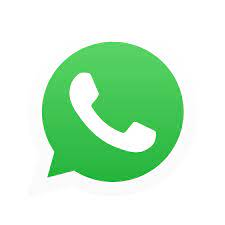

In [216]:
img = cv2.imread('download.jpg') 
cv2_imshow(img)

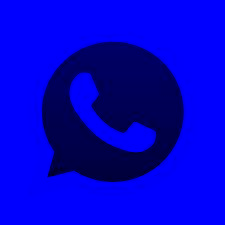

In [217]:
img = cv2.imread('download.jpg') 
ilumination1 = img
ilumination1[:,:,1:]=0
cv2_imshow(ilumination1)

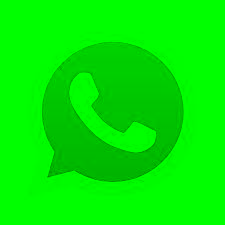

In [218]:
img = cv2.imread('download.jpg') 
ilumination2 = img
ilumination2[:,:,0]=0
ilumination2[:,:,2]=0
cv2_imshow(ilumination2)

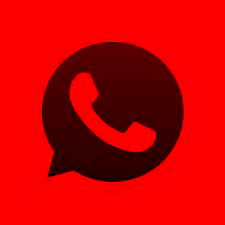

In [219]:
img = cv2.imread('download.jpg') 
ilumination3 = img
ilumination3[:,:,0]=0
ilumination3[:,:,1]=0
cv2_imshow(ilumination3)

In [220]:
media = ( img[:,:,0] + img[:,:,1] + img[:,:,2] ) / 3
media.shape

(225, 225)

Pegando apenas a parte vermelha da imagem e considerando-a como preto e branco

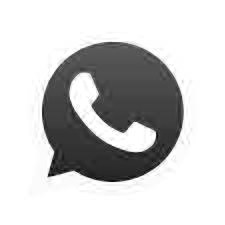

In [221]:
red = ilumination3[:,:,2]
cv2_imshow(red)

In [222]:
normalizado = red/255
linhas, colunas = normalizado.shape
linhas, colunas

(225, 225)

In [223]:
a = -1
b = 8

Matriz_transformacao = [[a, a, a],
                        [a, b, a],
                        [a, a, a]]                        
                        
Matriz_transformacao = np.array(Matriz_transformacao)
Matriz_transformacao

array([[0.11111111, 0.11111111, 0.11111111],
       [0.11111111, 0.11111111, 0.11111111],
       [0.11111111, 0.11111111, 0.11111111]])

In [224]:
img_saida = normalizado
for i in range(1, linhas, 3):
    for j in range(1, colunas, 3):
        img_saida[i-1:i+2, j-1:j+2] = np.sum(normalizado[i-1:i+2, j-1:j+2] * Matriz_transformacao)

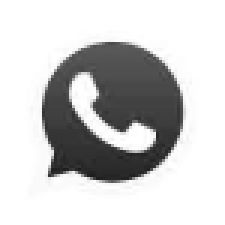

In [225]:
img_saida = img_saida*255
cv2_imshow(img_saida)

In [226]:
df = pd.DataFrame(normalizado)
df.to_excel('excel.xlsx')